In [130]:
print("Welcome to Movie Recommendation System")
print("Our Machine Learning Project")
print("Project Started Successfully!")

Welcome to Movie Recommendation System
Our Machine Learning Project
Project Started Successfully!


In [131]:
!pip install pandas numpy scikit-learn gradio

In [132]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.neighbors import NearestNeighbors

import gradio as gr

In [133]:
print("All Libraries Imported Successfully!")
print("Ready to Build Movie Recommendation System")

All Libraries Imported Successfully!
Ready to Build Movie Recommendation System


In [134]:
movies = pd.read_csv('/content/tmdb_5000_movies (1) (1).csv')

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [135]:
movies.head()

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


In [136]:
print("Dataset Shape:", movies.shape)

Dataset Shape: (4803, 20)


In [137]:
print(movies.columns)

Index(['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language',
       'original_title', 'overview', 'popularity', 'production_companies',
       'production_countries', 'release_date', 'revenue', 'runtime',
       'spoken_languages', 'status', 'tagline', 'title', 'vote_average',
       'vote_count'],
      dtype='object')


In [138]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

In [139]:
print(movies.isnull().sum())

budget                     0
genres                     0
homepage                3091
id                         0
keywords                   0
original_language          0
original_title             0
overview                   3
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                  844
title                      0
vote_average               0
vote_count                 0
dtype: int64


In [140]:
movies.sample(5)


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
4649,0,"[{""id"": 18, ""name"": ""Drama""}, {""id"": 53, ""name...",http://www.shotgunstories.com/,12247,"[{""id"": 380, ""name"": ""brother brother relation...",en,Shotgun Stories,Shotgun Stories tracks a feud that erupts betw...,5.251143,"[{""name"": ""Upload Films"", ""id"": 6724}, {""name""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-10-01,0,92.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,Two families. One feud. No going back.,Shotgun Stories,6.9,57
471,85000000,"[{""id"": 35, ""name"": ""Comedy""}, {""id"": 14, ""nam...",NaN,9678,"[{""id"": 494, ""name"": ""father son relationship""...",en,Little Nicky,After the lord of darkness decides he will not...,18.335992,"[{""name"": ""New Line Cinema"", ""id"": 12}, {""name...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2000-11-10,0,90.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,He's Never Been To Earth. He's Never Even Slep...,Little Nicky,5.2,438
1987,24000000,"[{""id"": 14, ""name"": ""Fantasy""}, {""id"": 16, ""na...",NaN,4935,"[{""id"": 334, ""name"": ""flying""}, {""id"": 616, ""n...",ja,ハウルの動く城,"When Sophie, a shy young woman, is cursed with...",49.549984,"[{""name"": ""Studio Ghibli"", ""id"": 10342}, {""nam...","[{""iso_3166_1"": ""JP"", ""name"": ""Japan""}]",2004-11-19,234710455,119.0,"[{""iso_639_1"": ""ja"", ""name"": ""\u65e5\u672c\u8a...",Released,The two lived there,Howl's Moving Castle,8.2,1991
1952,25000000,"[{""id"": 53, ""name"": ""Thriller""}, {""id"": 80, ""n...",NaN,109091,"[{""id"": 496, ""name"": ""poetry""}, {""id"": 10909, ...",en,The Counselor,A rich and successful lawyer named Counselor i...,35.022029,"[{""name"": ""Ingenious Media"", ""id"": 290}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2013-10-25,71009334,117.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,Sin Is A Choice.,The Counselor,5.0,712
2472,16000000,"[{""id"": 35, ""name"": ""Comedy""}, {""id"": 18, ""nam...",http://thewomen.warnerbros.com/index.html,13972,"[{""id"": 9749, ""name"": ""beauty salon""}, {""id"": ...",en,The Women,"The story centers on a group of gossipy, high-...",8.832100,"[{""name"": ""New Line Cinema"", ""id"": 12}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2008-09-12,50007546,114.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,NaN,The Women,4.6,96


In [141]:
movies[['title', 'genres', 'overview', 'vote_average']].head(10)

,title,genres,overview,vote_average
0,Avatar,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","In the 22nd century, a paraplegic Marine is di...",7.2
1,Pirates of the Caribbean: At World's End,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","Captain Barbossa, long believed to be dead, ha...",6.9
2,Spectre,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",A cryptic message from Bond’s past sends him o...,6.3
3,The Dark Knight Rises,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",Following the death of District Attorney Harve...,7.6
4,John Carter,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","John Carter is a war-weary, former military ca...",6.1
5,Spider-Man 3,"[{""id"": 14, ""name"": ""Fantasy""}, {""id"": 28, ""na...",The seemingly invincible Spider-Man goes up ag...,5.9
6,Tangled,"[{""id"": 16, ""name"": ""Animation""}, {""id"": 10751...",When the kingdom's most wanted-and most charmi...,7.4
7,Avengers: Age of Ultron,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",When Tony Stark tries to jumpstart a dormant p...,7.3
8,Harry Potter and the Half-Blood Prince,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","As Harry begins his sixth year at Hogwarts, he...",7.4
9,Batman v Superman: Dawn of Justice,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",Fearing the actions of a god-like Super Hero l...,5.7


In [142]:
movies = movies[['id', 'title', 'genres', 'keywords', 'overview', 'vote_average']]

print("Important Columns Selected Successfully!")

Important Columns Selected Successfully!


In [143]:
print(movies.isnull().sum())

id              0
title           0
genres          0
keywords        0
overview        3
vote_average    0
dtype: int64


In [144]:
movies.dropna(inplace=True)

print("Missing Values Removed Successfully!")

Missing Values Removed Successfully!


In [145]:
print("Duplicate Movies:", movies.duplicated().sum())

Duplicate Movies: 0


In [146]:
movies.drop_duplicates(inplace=True)

print("Duplicate Movies Removed Successfully!")

Duplicate Movies Removed Successfully!


In [147]:
print("Final Dataset Shape:", movies.shape)

movies.head()

Final Dataset Shape: (4800, 6)


,id,title,genres,keywords,overview,vote_average
0,19995,Avatar,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...","In the 22nd century, a paraplegic Marine is di...",7.2
1,285,Pirates of the Caribbean: At World's End,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...","Captain Barbossa, long believed to be dead, ha...",6.9
2,206647,Spectre,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",A cryptic message from Bond’s past sends him o...,6.3
3,49026,The Dark Knight Rises,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...","[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",Following the death of District Attorney Harve...,7.6
4,49529,John Carter,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 818, ""name"": ""based on novel""}, {""id"":...","John Carter is a war-weary, former military ca...",6.1


In [148]:
print("Movie Genres:")
print(movies['genres'].iloc[0])

print("\nMovie Keywords:")
print(movies['keywords'].iloc[0])

Movie Genres:
[{"id": 28, "name": "Action"}, {"id": 12, "name": "Adventure"}, {"id": 14, "name": "Fantasy"}, {"id": 878, "name": "Science Fiction"}]

Movie Keywords:
[{"id": 1463, "name": "culture clash"}, {"id": 2964, "name": "future"}, {"id": 3386, "name": "space war"}, {"id": 3388, "name": "space colony"}, {"id": 3679, "name": "society"}, {"id": 3801, "name": "space travel"}, {"id": 9685, "name": "futuristic"}, {"id": 9840, "name": "romance"}, {"id": 9882, "name": "space"}, {"id": 9951, "name": "alien"}, {"id": 10148, "name": "tribe"}, {"id": 10158, "name": "alien planet"}, {"id": 10987, "name": "cgi"}, {"id": 11399, "name": "marine"}, {"id": 13065, "name": "soldier"}, {"id": 14643, "name": "battle"}, {"id": 14720, "name": "love affair"}, {"id": 165431, "name": "anti war"}, {"id": 193554, "name": "power relations"}, {"id": 206690, "name": "mind and soul"}, {"id": 209714, "name": "3d"}]


In [149]:
import ast

def convert(text):
    result = []

    for item in ast.literal_eval(text):
        result.append(item['name'])

    return result

In [150]:
movies['genres'] = movies['genres'].apply(convert)

print(movies['genres'].head())

0    [Action, Adventure, Fantasy, Science Fiction]
1                     [Adventure, Fantasy, Action]
2                       [Action, Adventure, Crime]
3                 [Action, Crime, Drama, Thriller]
4             [Action, Adventure, Science Fiction]
Name: genres, dtype: object


In [151]:
movies['keywords'] = movies['keywords'].apply(convert)

print(movies['keywords'].head())

0    [culture clash, future, space war, space colon...
1    [ocean, drug abuse, exotic island, east india ...
2    [spy, based on novel, secret agent, sequel, mi...
3    [dc comics, crime fighter, terrorist, secret i...
4    [based on novel, mars, medallion, space travel...
Name: keywords, dtype: object


In [152]:
print(movies['overview'].head())

0    In the 22nd century, a paraplegic Marine is di...
1    Captain Barbossa, long believed to be dead, ha...
2    A cryptic message from Bond’s past sends him o...
3    Following the death of District Attorney Harve...
4    John Carter is a war-weary, former military ca...
Name: overview, dtype: object


In [153]:
print("Missing Overview:", movies['overview'].isnull().sum())

Missing Overview: 0


In [154]:
movies['overview'] = movies['overview'].apply(lambda x: x.lower())

In [155]:
print(movies['overview'].head())

0    in the 22nd century, a paraplegic marine is di...
1    captain barbossa, long believed to be dead, ha...
2    a cryptic message from bond’s past sends him o...
3    following the death of district attorney harve...
4    john carter is a war-weary, former military ca...
Name: overview, dtype: object


In [156]:
movies['tags'] = movies['genres'] + movies['keywords'] + movies['overview'].apply(lambda x: x.split())

In [157]:
print(movies[['title', 'tags']].head())

                                      title  \
0                                    Avatar   
1  Pirates of the Caribbean: At World's End   
2                                   Spectre   
3                     The Dark Knight Rises   
4                               John Carter   

                                                tags  
0  [Action, Adventure, Fantasy, Science Fiction, ...  
1  [Adventure, Fantasy, Action, ocean, drug abuse...  
2  [Action, Adventure, Crime, spy, based on novel...  
3  [Action, Crime, Drama, Thriller, dc comics, cr...  
4  [Action, Adventure, Science Fiction, based on ...  


In [158]:
print(movies.columns)

Index(['id', 'title', 'genres', 'keywords', 'overview', 'vote_average',
       'tags'],
      dtype='object')


In [159]:
movies['tags'] = movies['tags'].apply(lambda x: " ".join(x))

In [160]:
movies['tags'] = movies['tags'].apply(lambda x: x.lower())

In [161]:
print(movies[['title', 'tags']].head(5))

                                      title  \
0                                    Avatar   
1  Pirates of the Caribbean: At World's End   
2                                   Spectre   
3                     The Dark Knight Rises   
4                               John Carter   

                                                tags  
0  action adventure fantasy science fiction cultu...  
1  adventure fantasy action ocean drug abuse exot...  
2  action adventure crime spy based on novel secr...  
3  action crime drama thriller dc comics crime fi...  
4  action adventure science fiction based on nove...  


In [162]:
print(type(movies['tags'].iloc[0]))

<class 'str'>


In [163]:
cv = CountVectorizer(max_features=5000, stop_words='english')

In [164]:
vectors = cv.fit_transform(movies['tags']).toarray()

In [165]:
print("Vector Shape:", vectors.shape)

Vector Shape: (4800, 5000)


In [166]:
print(vectors[0])

[0 0 0 ... 0 0 0]


In [167]:
knn = NearestNeighbors(
    n_neighbors=6,
    metric='cosine',
    algorithm='brute'
)

In [168]:
knn.fit(vectors)

NearestNeighbors(algorithm='brute', metric='cosine', n_neighbors=6)

In [169]:
print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [170]:
distances, indices = knn.kneighbors([vectors[0]])

In [171]:
print("Distances:", distances)
print("Movie Indices:", indices)

Distances: [[0.         0.5454809  0.56459113 0.56909659 0.57190748 0.58272301]]
Movie Indices: [[   0 2403  373 1531 4330 2015]]


In [172]:
def recommend(movie_name):

    movie_index = movies[movies['title'] == movie_name].index[0]

    distances, indices = knn.kneighbors(
        [vectors[movie_index]]
    )

    recommended_movies = []

    for i in indices[0][1:6]:

        recommended_movies.append(
            movies.iloc[i]['title']
        )

    return recommended_movies

In [173]:
recommend('Avatar')

['Aliens', 'Mission to Mars', 'Moonraker', 'Silent Running', 'Spaceballs']

In [174]:
recommend('Titanic')

['The Notebook',
 'Captain Phillips',
 'Romance & Cigarettes',
 'Veer-Zaara',
 'Love Letters']

In [175]:
movie_list = movies['title'].values

In [176]:
movie_list = movies['title'].tolist()

print("Total Movies:", len(movie_list))
print("First 5 Movies:", movie_list[:5])

Total Movies: 4800
First 5 Movies: ['Avatar', "Pirates of the Caribbean: At World's End", 'Spectre', 'The Dark Knight Rises', 'John Carter']


In [177]:
def movie_recommendation_ui(movie):
    recommendations = recommend(movie)

    return "\n".join(recommendations)

In [178]:
import gradio as gr

interface = gr.Interface(
    fn=movie_recommendation_ui,

    inputs=gr.Dropdown(
        choices=movie_list,
        label="Select Your Favourite Movie"
    ),

    outputs=gr.Textbox(
        label="Recommended Movies",
        lines=8
    ),

    title="Movie Recommendation System",

    description="Select a movie and discover similar movies!"
)

interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f6e932738ccbfc6032.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [179]:
interface.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f6e932738ccbfc6032.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [180]:
original_movies = pd.read_csv('/content/tmdb_5000_movies (1) (1).csv')

# Remove extra spaces from column names
original_movies.columns = original_movies.columns.str.strip()

print("Available Columns:")
print(original_movies.columns.tolist())

print("\nPoster Column Available?")
print('poster_path' in original_movies.columns)

Available Columns:
['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']

Poster Column Available?
False


In [181]:
print(original_movies.columns.tolist())

['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']


In [182]:
print("Total Movies:", len(movies))

print(movies[['id', 'title', 'vote_average']].head(10))

Total Movies: 4800
       id                                     title  vote_average
0   19995                                    Avatar           7.2
1     285  Pirates of the Caribbean: At World's End           6.9
2  206647                                   Spectre           6.3
3   49026                     The Dark Knight Rises           7.6
4   49529                               John Carter           6.1
5     559                              Spider-Man 3           5.9
6   38757                                   Tangled           7.4
7   99861                   Avengers: Age of Ultron           7.3
8     767    Harry Potter and the Half-Blood Prince           7.4
9  209112        Batman v Superman: Dawn of Justice           5.7


In [183]:
def get_movie_rating(movie_name):
    rating = movies[movies['title'] == movie_name]['vote_average'].values[0]
    return rating

print("Avatar Rating:", get_movie_rating("Avatar"))

Avatar Rating: 7.2


In [184]:
def get_movie_details(movie_name):
    movie = movies[movies['title'] == movie_name].iloc[0]

    title = movie['title']
    rating = movie['vote_average']
    overview = movie['overview']

    return f"""
    Movie Name: {title}

    Rating: {rating}/10

    Description: {overview}
    """

print(get_movie_details("Avatar"))


    Movie Name: Avatar

    Rating: 7.2/10

    Description: in the 22nd century, a paraplegic marine is dispatched to the moon pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization.
    


In [185]:
def top_rated_movies():
    top_movies = movies.sort_values(
        by='vote_average',
        ascending=False
    )

    return top_movies[['title', 'vote_average']].head(10)

print(top_rated_movies())

                         title  vote_average
4045     Dancer, Texas Pop. 81          10.0
3519          Stiff Upper Lips          10.0
4662            Little Big Top          10.0
4247     Me You and Five Bucks          10.0
3992                 Sardaarji           9.5
2386            One Man's Hero           9.3
1881  The Shawshank Redemption           8.5
2970        There Goes My Baby           8.5
3337             The Godfather           8.4
2796     The Prisoner of Zenda           8.4


In [186]:
def recommend_with_ratings(movie_name):

    movie_index = movies[movies['title'] == movie_name].index[0]

    distances, indices = knn.kneighbors([vectors[movie_index]])

    result = []

    for i in indices[0][1:6]:

        title = movies.iloc[i]['title']
        rating = movies.iloc[i]['vote_average']

        result.append(f"{title} - Rating: {rating}/10")

    return "\n".join(result)


print(recommend_with_ratings("Avatar"))

Aliens - Rating: 7.7/10
Mission to Mars - Rating: 5.7/10
Moonraker - Rating: 5.9/10
Silent Running - Rating: 6.3/10
Spaceballs - Rating: 6.7/10


In [187]:
def movie_recommendation_ui(selected_movie):

    recommendations = recommend_with_ratings(selected_movie)

    return recommendations


interface = gr.Interface(
    fn=movie_recommendation_ui,

    inputs=gr.Dropdown(
        choices=movie_list,
        label="Select Your Favourite Movie"
    ),

    outputs=gr.Textbox(
        label="Recommended Movies with Ratings",
        lines=10
    ),

    title="CineMind - Movie Recommendation System",

    description="Select your favourite movie and discover similar movies with ratings!"
)

interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a9b92a88f82f7787cb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [188]:
def search_movie(movie_name):

    result = movies[
        movies['title'].str.contains(
            movie_name,
            case=False,
            na=False
        )
    ]

    if result.empty:
        return "Movie Not Found!"

    return result[['title', 'vote_average']].head(10).to_string(index=False)


print(search_movie("Avatar"))

 title  vote_average
Avatar           7.2


In [189]:
def movies_by_genre(genre_name):

    result = movies[
        movies['genres'].apply(
            lambda x: any(
                genre_name.lower() in genre.lower()
                for genre in x
            )
        )
    ]

    return result[['title', 'vote_average']].head(10)


print(movies_by_genre("Action"))

                                       title  vote_average
0                                     Avatar           7.2
1   Pirates of the Caribbean: At World's End           6.9
2                                    Spectre           6.3
3                      The Dark Knight Rises           7.6
4                                John Carter           6.1
5                               Spider-Man 3           5.9
7                    Avengers: Age of Ultron           7.3
9         Batman v Superman: Dawn of Justice           5.7
10                          Superman Returns           5.4
11                         Quantum of Solace           6.1


In [190]:
total_movies = len(movies)

average_rating = movies['vote_average'].mean()

highest_rating = movies['vote_average'].max()

lowest_rating = movies['vote_average'].min()

print("CineMind Movie Statistics")
print("-------------------------")
print("Total Movies:", total_movies)
print("Average Rating:", round(average_rating, 2))
print("Highest Rating:", highest_rating)
print("Lowest Rating:", lowest_rating)

CineMind Movie Statistics
-------------------------
Total Movies: 4800
Average Rating: 6.09
Highest Rating: 10.0
Lowest Rating: 0.0


In [191]:
all_genres = []

for genre_list in movies['genres']:
    for genre in genre_list:
        if genre not in all_genres:
            all_genres.append(genre)

all_genres.sort()

print("Available Movie Genres:")
print(all_genres)

Available Movie Genres:
['Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Family', 'Fantasy', 'Foreign', 'History', 'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'TV Movie', 'Thriller', 'War', 'Western']


In [192]:
def genre_recommendation_ui(selected_genre):

    result = movies_by_genre(selected_genre)

    return result.to_string(index=False)


genre_interface = gr.Interface(
    fn=genre_recommendation_ui,

    inputs=gr.Dropdown(
        choices=all_genres,
        label="Select Movie Genre"
    ),

    outputs=gr.Textbox(
        label="Movies by Genre",
        lines=12
    ),

    title="CineMind - Genre Based Movie Search",

    description="Select a genre and explore movies!"
)

genre_interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bb972902349fa01b53.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [193]:
import pickle

model_data = {
    'movies': movies,
    'vectors': vectors,
    'knn': knn
}

with open('movie_recommendation_model.pkl', 'wb') as file:
    pickle.dump(model_data, file)

print("Model Saved Successfully!")

Model Saved Successfully!


In [194]:
from google.colab import files

files.download('movie_recommendation_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [195]:
import pickle

with open('movie_recommendation_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

loaded_movies = loaded_model['movies']
loaded_vectors = loaded_model['vectors']
loaded_knn = loaded_model['knn']

print("Model Loaded Successfully!")
print("Total Movies:", len(loaded_movies))

Model Loaded Successfully!
Total Movies: 4800


In [196]:
# Reset movie index
movies = movies.reset_index(drop=True)

# Create movie vectors again
vectors = cv.fit_transform(movies['tags']).toarray()

# Train KNN model again
knn = NearestNeighbors(
    n_neighbors=6,
    metric='cosine',
    algorithm='brute'
)

knn.fit(vectors)

print("Final Model Prepared Successfully!")

Final Model Prepared Successfully!


In [197]:
import pickle

model_data = {
    'movies': movies,
    'vectors': vectors,
    'knn': knn
}

with open('movie_recommendation_model.pkl', 'wb') as file:
    pickle.dump(model_data, file)

print("Updated Model Saved Successfully!")

Updated Model Saved Successfully!


In [198]:
def final_movie_app(movie_name, genre_name):

    movie_result = recommend_with_ratings(movie_name)

    genre_result = movies_by_genre(genre_name)

    return (
        "MOVIE RECOMMENDATIONS:\n\n"
        + movie_result
        + "\n\nMOVIES BY GENRE:\n\n"
        + genre_result[['title', 'vote_average']].to_string(index=False)
    )


final_interface = gr.Interface(
    fn=final_movie_app,

    inputs=[
        gr.Dropdown(
            choices=movie_list,
            label="Select Favourite Movie"
        ),

        gr.Dropdown(
            choices=all_genres,
            label="Select Movie Genre"
        )
    ],

    outputs=gr.Textbox(
        label="CineMind Results",
        lines=20
    ),

    title="CineMind - Movie Recommendation System",

    description="Discover similar movies and explore movies by genre."
)

final_interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://742df64ca82c97f463.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [199]:
from google.colab import files

files.download('/content/tmdb_5000_movies (1) (1).csv')

files.download('/content/movie_recommendation_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [200]:
def evaluate_recommendation(movie_name):

    movie_index = movies[
        movies['title'] == movie_name
    ].index[0]

    distances, indices = knn.kneighbors(
        [vectors[movie_index]]
    )

    recommended_indices = indices[0][1:6]

    original_genres = set(movies.iloc[movie_index]['genres'])

    relevant_movies = 0

    for i in recommended_indices:

        recommended_genres = set(movies.iloc[i]['genres'])

        if original_genres.intersection(recommended_genres):
            relevant_movies += 1

    precision = relevant_movies / 5

    print("Movie:", movie_name)
    print("Relevant Recommendations:", relevant_movies)
    print("Precision@5:", round(precision, 2))


evaluate_recommendation("Avatar")

Movie: Avatar
Relevant Recommendations: 5
Precision@5: 1.0


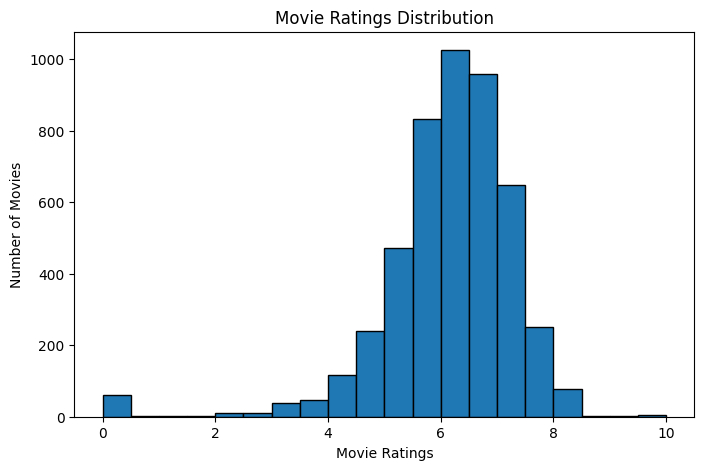

In [201]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    movies['vote_average'],
    bins=20,
    edgecolor='black'
)

plt.title("Movie Ratings Distribution")
plt.xlabel("Movie Ratings")
plt.ylabel("Number of Movies")

plt.show()

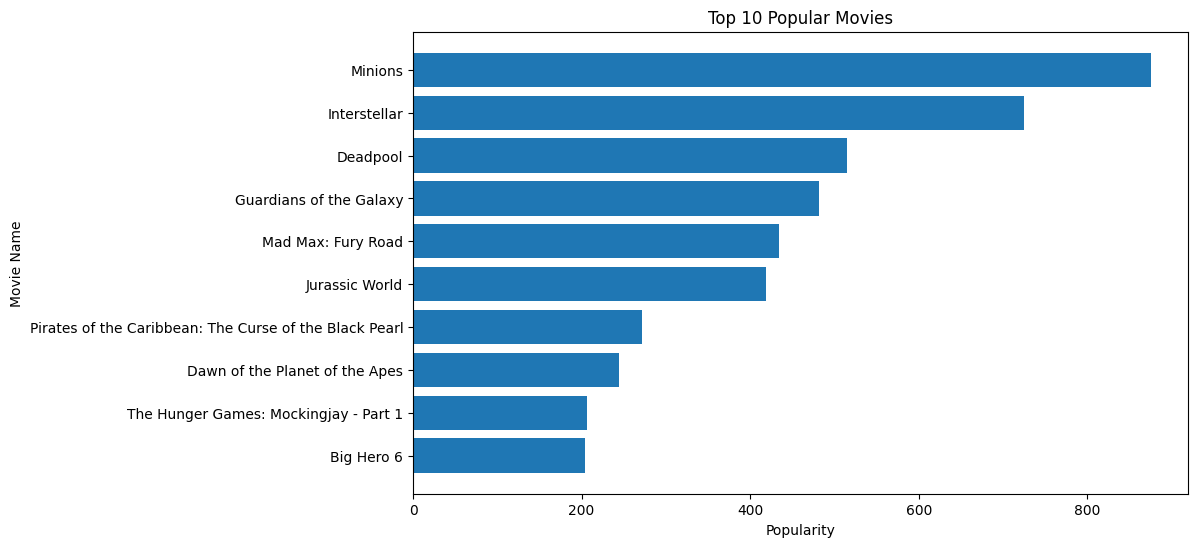

In [203]:


original_movies = pd.read_csv('/content/tmdb_5000_movies (1) (1).csv')

top_movies = original_movies.sort_values(
    by='popularity',
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_movies['title'],
    top_movies['popularity']
)

plt.title("Top 10 Popular Movies")
plt.xlabel("Popularity")
plt.ylabel("Movie Name")

plt.gca().invert_yaxis()

plt.show()

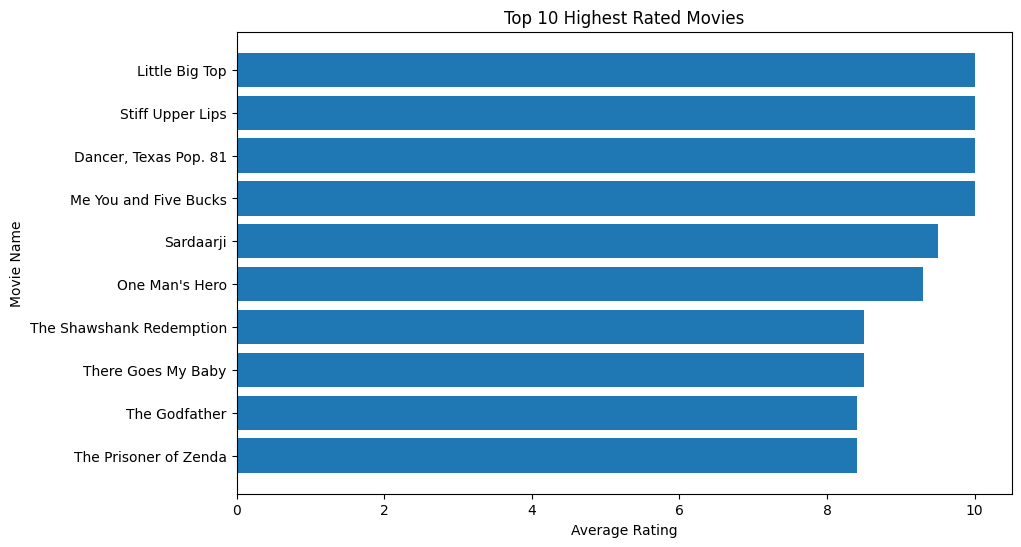

In [204]:


top_rated = original_movies.sort_values(
    by='vote_average',
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_rated['title'],
    top_rated['vote_average']
)

plt.title("Top 10 Highest Rated Movies")
plt.xlabel("Average Rating")
plt.ylabel("Movie Name")

plt.gca().invert_yaxis()

plt.show()

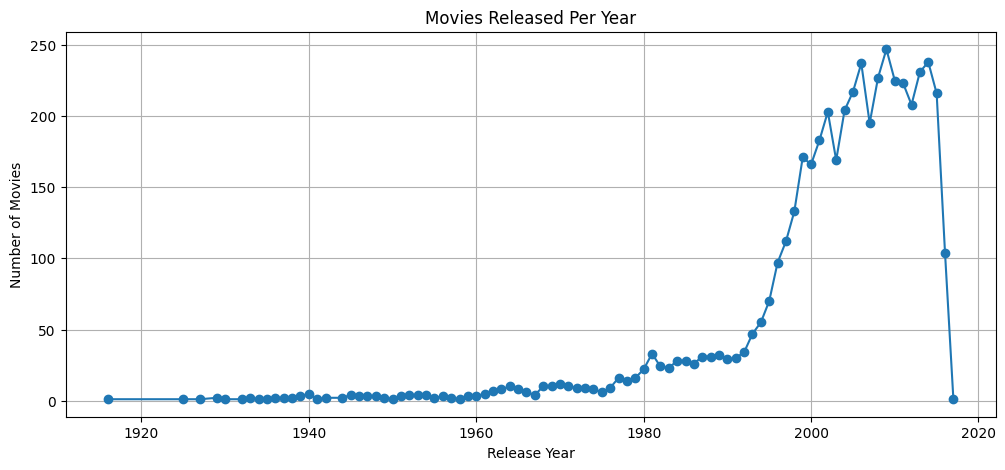

In [205]:
original_movies['release_date'] = pd.to_datetime(
    original_movies['release_date'],
    errors='coerce'
)

original_movies['release_year'] = (
    original_movies['release_date'].dt.year
)

year_counts = original_movies['release_year'].value_counts().sort_index()

plt.figure(figsize=(12, 5))

plt.plot(
    year_counts.index,
    year_counts.values,
    marker='o'
)

plt.title("Movies Released Per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")

plt.grid(True)
plt.show()

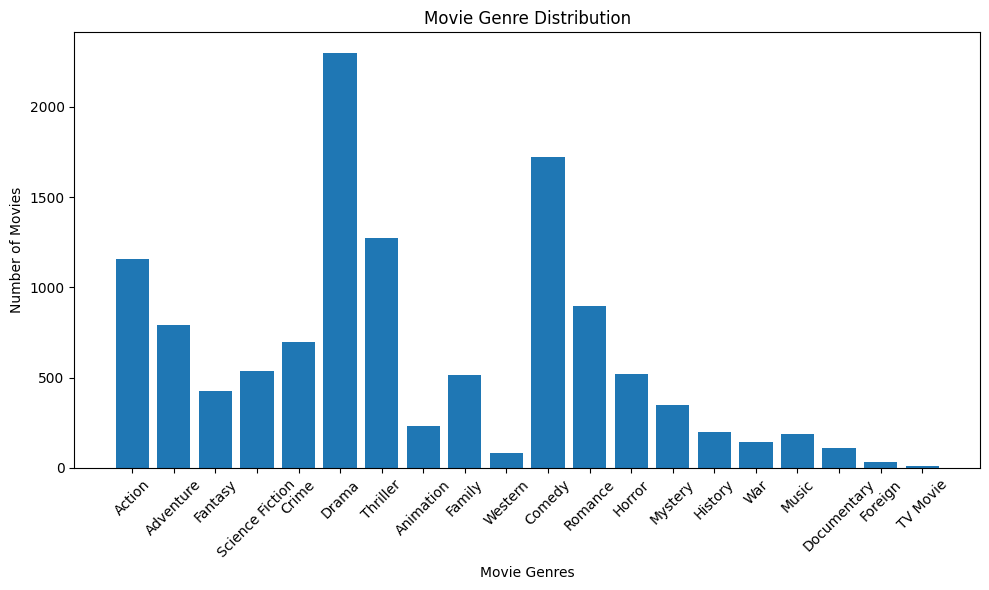

In [206]:
from collections import Counter

genre_list = []

for genres in original_movies['genres'].dropna():
    genre_data = ast.literal_eval(genres)

    for genre in genre_data:
        genre_list.append(genre['name'])

genre_counts = Counter(genre_list)

genre_names = list(genre_counts.keys())
genre_values = list(genre_counts.values())

plt.figure(figsize=(10, 6))

plt.bar(genre_names, genre_values)

plt.title("Movie Genre Distribution")
plt.xlabel("Movie Genres")
plt.ylabel("Number of Movies")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

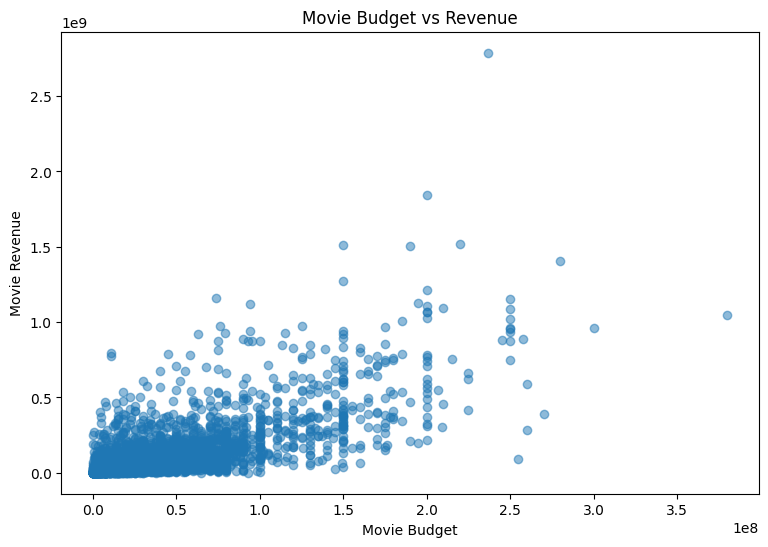

In [207]:
budget_revenue = original_movies[
    (original_movies['budget'] > 0) &
    (original_movies['revenue'] > 0)
]

plt.figure(figsize=(9, 6))

plt.scatter(
    budget_revenue['budget'],
    budget_revenue['revenue'],
    alpha=0.5
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Movie Budget")
plt.ylabel("Movie Revenue")

plt.show()

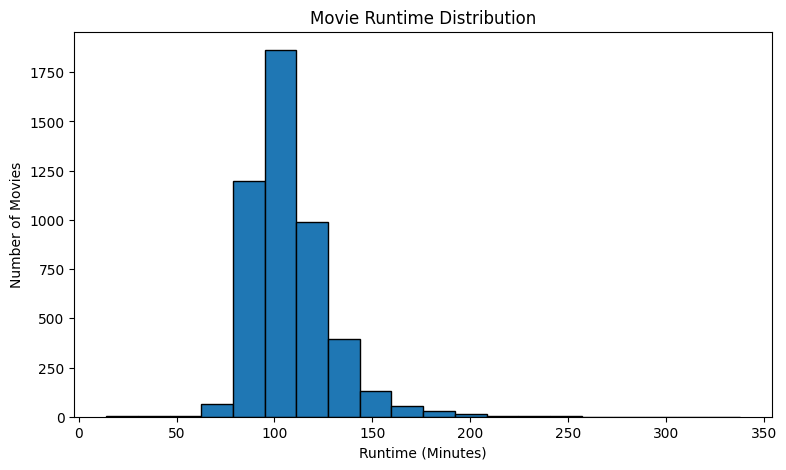

In [208]:


runtime_data = original_movies[
    original_movies['runtime'] > 0
]

plt.figure(figsize=(9, 5))

plt.hist(
    runtime_data['runtime'],
    bins=20,
    edgecolor='black'
)

plt.title("Movie Runtime Distribution")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Number of Movies")

plt.show()

Text(0, 0.5, 'Number of Movies')

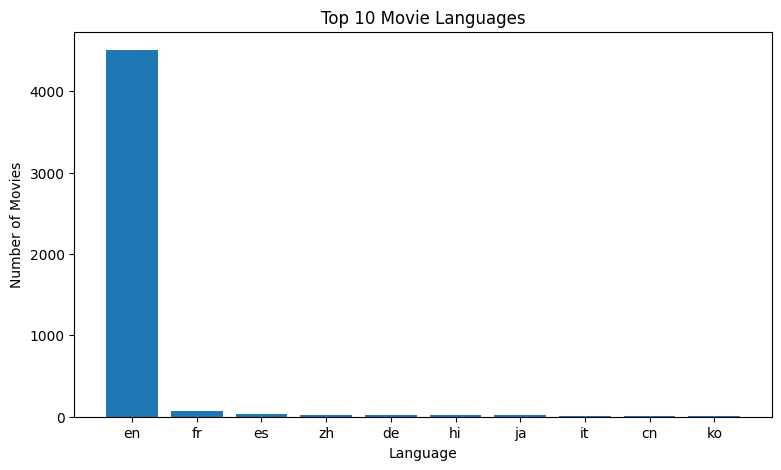

In [209]:
language_counts = original_movies[
    'original_language'
].value_counts().head(10)

plt.figure(figsize=(9, 5))

plt.bar(
    language_counts.index,
    language_counts.values
)

plt.title("Top 10 Movie Languages")
plt.xlabel("Language")
plt.ylabel("Number of Movies")


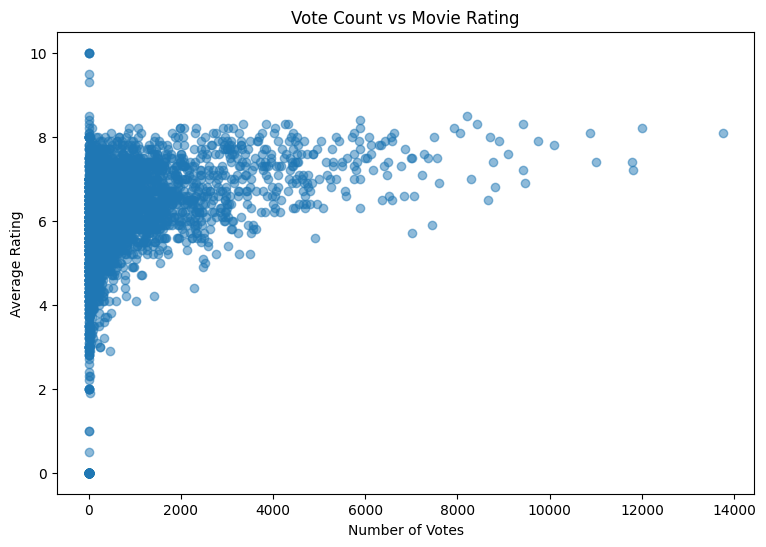

In [210]:
plt.figure(figsize=(9, 6))

plt.scatter(
    original_movies['vote_count'],
    original_movies['vote_average'],
    alpha=0.5
)

plt.title("Vote Count vs Movie Rating")
plt.xlabel("Number of Votes")
plt.ylabel("Average Rating")

plt.show()

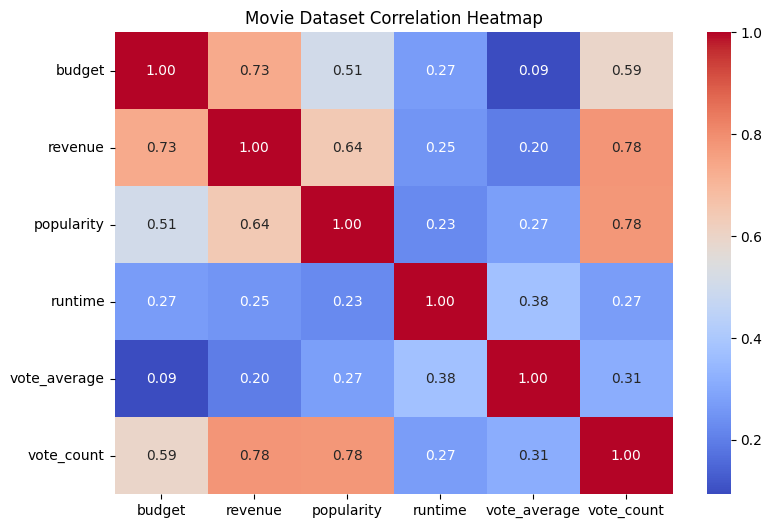

In [211]:
import seaborn as sns

numeric_data = original_movies[
    ['budget', 'revenue', 'popularity',
     'runtime', 'vote_average', 'vote_count']
]

correlation = numeric_data.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Movie Dataset Correlation Heatmap")

plt.show()

In [212]:
print("===== CineMind EDA Summary =====")

print("Total Movies:", len(original_movies))

print("Total Columns:", len(original_movies.columns))

print("Missing Values:", original_movies.isnull().sum().sum())

print("Duplicate Records:", original_movies.duplicated().sum())

print("Average Rating:",
      round(original_movies['vote_average'].mean(), 2))

print("Average Runtime:",
      round(original_movies['runtime'].mean(), 2))

print("Highest Popularity:",
      original_movies['popularity'].max())

print("Total Movie Languages:",
      original_movies['original_language'].nunique())

print("===== EDA Completed =====")

===== CineMind EDA Summary =====
Total Movies: 4803
Total Columns: 21
Missing Values: 3942
Duplicate Records: 0
Average Rating: 6.09
Average Runtime: 106.88
Highest Popularity: 875.581305
Total Movie Languages: 37
===== EDA Completed =====


In [213]:
test_movies = ["Avatar", "Titanic", "The Dark Knight",
               "Iron Man", "Spider-Man"]

evaluation_results = []

for movie_name in test_movies:

    movie_index = movies[
        movies['title'] == movie_name
    ].index[0]

    distances, indices = knn.kneighbors(
        [vectors[movie_index]]
    )

    recommended_indices = indices[0][1:6]

    original_genres = set(movies.iloc[movie_index]['genres'])

    relevant = 0

    for i in recommended_indices:

        recommended_genres = set(movies.iloc[i]['genres'])

        if original_genres.intersection(recommended_genres):
            relevant += 1

    precision = relevant / 5

    evaluation_results.append({
        "Movie": movie_name,
        "Precision@5": precision
    })

evaluation_df = pd.DataFrame(evaluation_results)

print(evaluation_df)

             Movie  Precision@5
0           Avatar          1.0
1          Titanic          1.0
2  The Dark Knight          1.0
3         Iron Man          1.0
4       Spider-Man          1.0


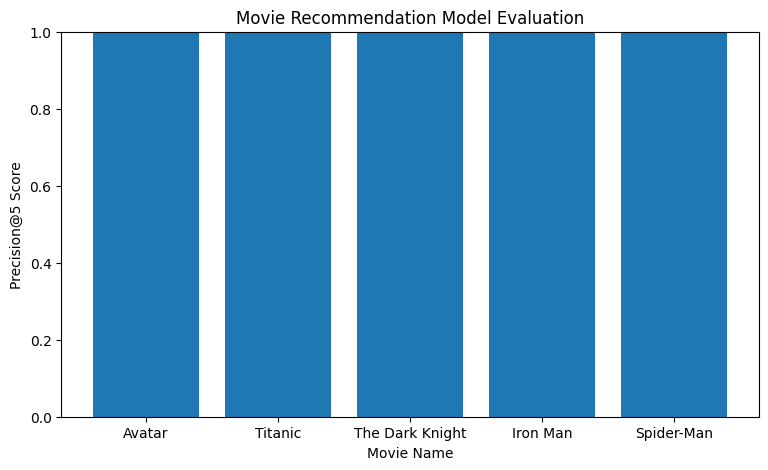

In [214]:
plt.figure(figsize=(9, 5))

plt.bar(
    evaluation_df['Movie'],
    evaluation_df['Precision@5']
)

plt.title("Movie Recommendation Model Evaluation")
plt.xlabel("Movie Name")
plt.ylabel("Precision@5 Score")

plt.ylim(0, 1)
plt.show()

In [215]:
average_precision = evaluation_df['Precision@5'].mean()

best_movie = evaluation_df.loc[
    evaluation_df['Precision@5'].idxmax()
]

print("===== Model Performance =====")

print("Average Precision@5:",
      round(average_precision, 2))

print("Best Evaluated Movie:",
      best_movie['Movie'])

print("Best Precision@5:",
      round(best_movie['Precision@5'], 2))

===== Model Performance =====
Average Precision@5: 1.0
Best Evaluated Movie: Avatar
Best Precision@5: 1.0


In [216]:

from IPython.display import display, Markdown

report = f"""
# Movie recommendation system - Model Evaluation Report

## Project Details
- Project: Movie Recommendation System
- Algorithm: K-Nearest Neighbors (KNN)
- Feature Extraction: CountVectorizer
- Similarity Metric: Cosine Distance

## Evaluation Results
- Average Precision@5: {average_precision:.2f}
- Best Movie: {best_movie['Movie']}
- Best Precision@5: {best_movie['Precision@5']:.2f}

## Conclusion
The system recommends movies based on similar
genres, keywords and movie descriptions.
"""

display(Markdown(report))


# Movie recommendation system - Model Evaluation Report

## Project Details
- Project: Movie Recommendation System
- Algorithm: K-Nearest Neighbors (KNN)
- Feature Extraction: CountVectorizer
- Similarity Metric: Cosine Distance

## Evaluation Results
- Average Precision@5: 1.00
- Best Movie: Avatar
- Best Precision@5: 1.00

## Conclusion
The system recommends movies based on similar
genres, keywords and movie descriptions.


In [217]:
project_summary = {
    "Project Name": "Movie recommendation system",
    "Dataset": "TMDB 5000 Movies",
    "EDA": "Completed",
    "Data Preprocessing": "Completed",
    "Feature Extraction": "CountVectorizer",
    "Machine Learning Algorithm": "KNN",
    "Distance Metric": "Cosine",
    "Model Training": "Completed",
    "Model Evaluation": "Precision@5",
    "User Interface": "Gradio",
    "Recommendation System": "Completed"
}

for key, value in project_summary.items():
    print(key, ":", value)

print("\nMovie recommendation system Project Summary Completed!")

Project Name : Movie recommendation system
Dataset : TMDB 5000 Movies
EDA : Completed
Data Preprocessing : Completed
Feature Extraction : CountVectorizer
Machine Learning Algorithm : KNN
Distance Metric : Cosine
Model Training : Completed
Model Evaluation : Precision@5
User Interface : Gradio
Recommendation System : Completed

Movie recommendation system Project Summary Completed!
